# 12. 입력 가용성 저하 — 전체 검출 범위와 조건부 성능

    고장20종×500실행=10,000개를유지하고 고장별균형·seed42/43/44로센서입력만가렸다. 선택비율은**실행비율**이며전체샘플삭제율이아니다. 모델재학습·임계값재선택·라벨변경은없다. 이노트북은저장된실측표·그림만읽는다.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display,Markdown,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'experiments/sensor_availability/config.json').exists())
OUT=ROOT/'reports/sensor_availability'
def js(name): return json.loads((OUT/name).read_text(encoding='utf-8'))
def table(name): return pd.read_csv(OUT/'tables'/name)
def show(frame,title):
    display(frame.style.hide(axis='index').set_caption(title).format(precision=5,na_rep='해당 없음')
            .set_properties(**{'padding':'6px 9px','text-align':'left'})
            .set_table_styles([{'selector':'caption','props':[('text-align','left'),('font-weight','bold')]},
                              {'selector':'th','props':[('background-color','#eef3f6'),('text-align','left')]}]))
def figure(name): display(Image(filename=str(OUT/'figures'/name)))
baseline=js('baseline.json')
phm=js('sources/phm_definition_audit.json')
full=table('full_summary.csv')
summary=table('summary_mean_sd.csv')

## 1. 필수 결과: 전체/평가가능 분모를 함께 표시

    전체검출률=검출/전체10,000, 조건부검출률=검출/가용실행이다. 아래는3seed실측평균이며 분모정수는같고 검출수평균은소수가될수있다. 조건별부분가용은주실험에서0개이고,짧은공백대조는별도로집계한다.

평가불가 목표율,전체 실행,평가 가능,평가 불가,부분 가용,검출 평균,조건부 검출률,전체 검출률,가용시점 ROC-AUC,가용시점 F1
0.00%,10000,10000,0,0,"9,851.00",98.51%,98.51%,0.95393,0.92770
10.00%,10000,9000,1000,0,"8,864.00",98.49%,88.64%,0.95395,0.92757
25.00%,10000,7500,2500,0,"7,383.00",98.44%,73.83%,0.95395,0.92729
40.00%,10000,6000,4000,0,"5,906.67",98.44%,59.07%,0.95396,0.92688
53.10%,10000,4690,5310,0,"4,617.33",98.45%,46.17%,0.95393,0.92629


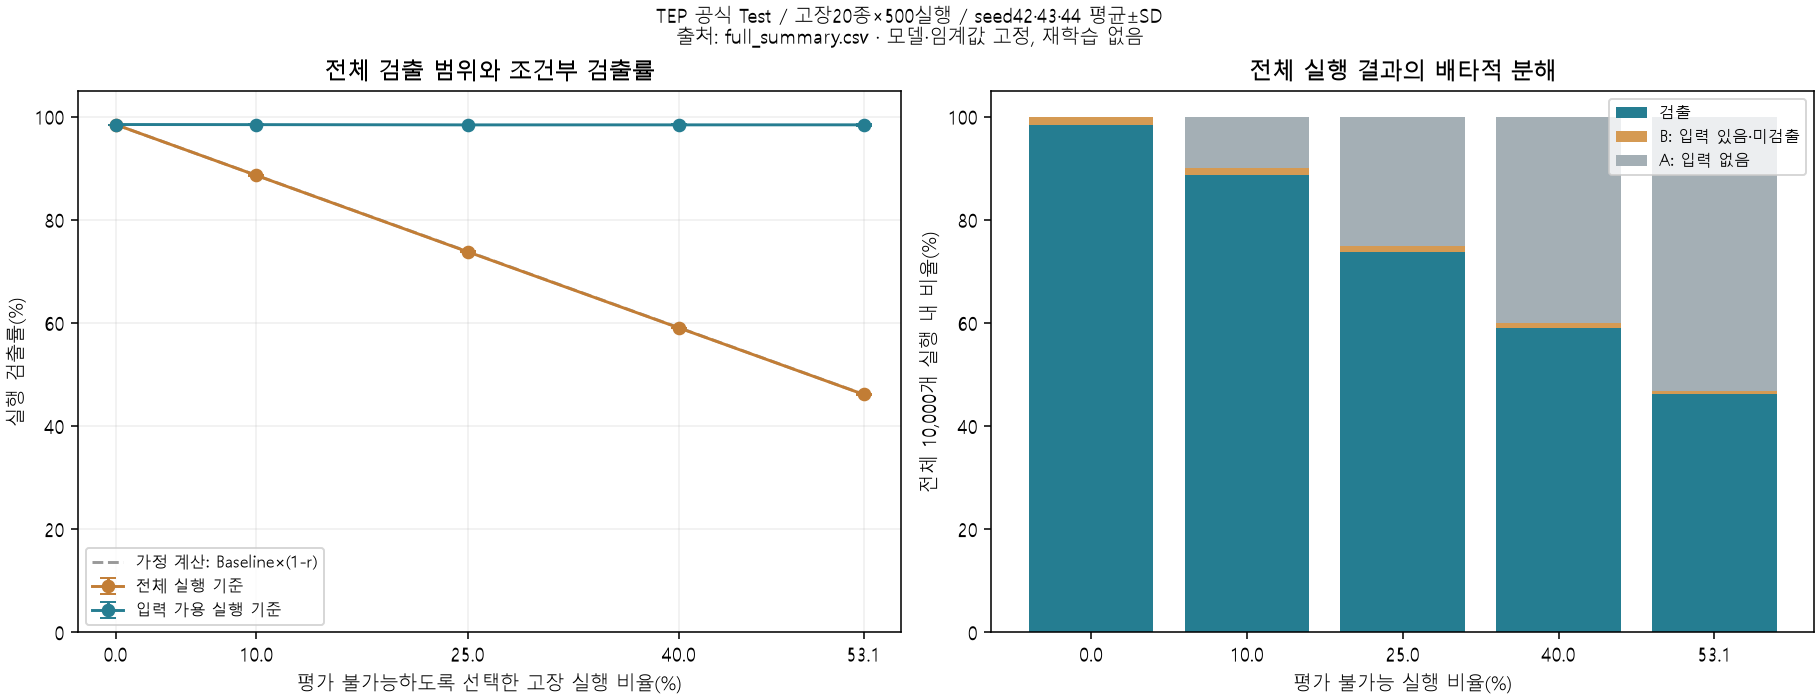

rate,seed,evaluable_fault_runs,unavailable_fault_runs,detected_fault_runs,conditional_detection_rate,overall_detection_rate
0.00000,42,10000,0,9851,0.98510,0.98510
0.00000,43,10000,0,9851,0.98510,0.98510
0.00000,44,10000,0,9851,0.98510,0.98510
0.10000,42,9000,1000,8859,0.98433,0.88590
0.10000,43,9000,1000,8871,0.98567,0.88710
0.10000,44,9000,1000,8862,0.98467,0.88620
0.25000,42,7500,2500,7378,0.98373,0.73780
0.25000,43,7500,2500,7389,0.98520,0.73890
0.25000,44,7500,2500,7382,0.98427,0.73820
0.40000,42,6000,4000,5901,0.98350,0.59010


In [2]:
show(table('compact_results.csv'),'0/10/25/40/53.1% 결과 / 검출률은%, AUC·F1은0~1, 실측3seed평균')
figure('coverage_and_detection.png')
detail=full[['rate','seed','evaluable_fault_runs','unavailable_fault_runs','detected_fault_runs','conditional_detection_rate','overall_detection_rate']]
show(detail,'각seed의 실제 정수 검출수 및 두 분모')
assert np.allclose(full.overall_detection_rate,(full.evaluable_fault_runs/10000)*full.conditional_detection_rate)

## 2. A: 입력 없음 / B: 입력은 있으나 미검출

    A+B+검출=10,000이다. A에는원래모델도검출하지못했던실행이포함되므로 A수와신규검출손실을구분한다. 53.1%에서5,310개의기회를없앴고기존검출실행의손실은약5,234개였다. 유효시점만의ROC-AUC/F1이유사해도전체검출범위는절반수준으로줄었다.

seed,cause_A_no_input,cause_B_input_but_no_detection,detected_fault_runs,baseline_detections_lost,lost_previously_detected_due_unavailability
42,5310,80,4610,5241,5241
43,5310,71,4619,5232,5232
44,5310,67,4623,5228,5228


rate,detection_roc_auc,detection_f1
0.00000,0.95393,0.92770
0.10000,0.95395,0.92757
0.25000,0.95395,0.92729
0.40000,0.95396,0.92688
0.53100,0.95393,0.92629


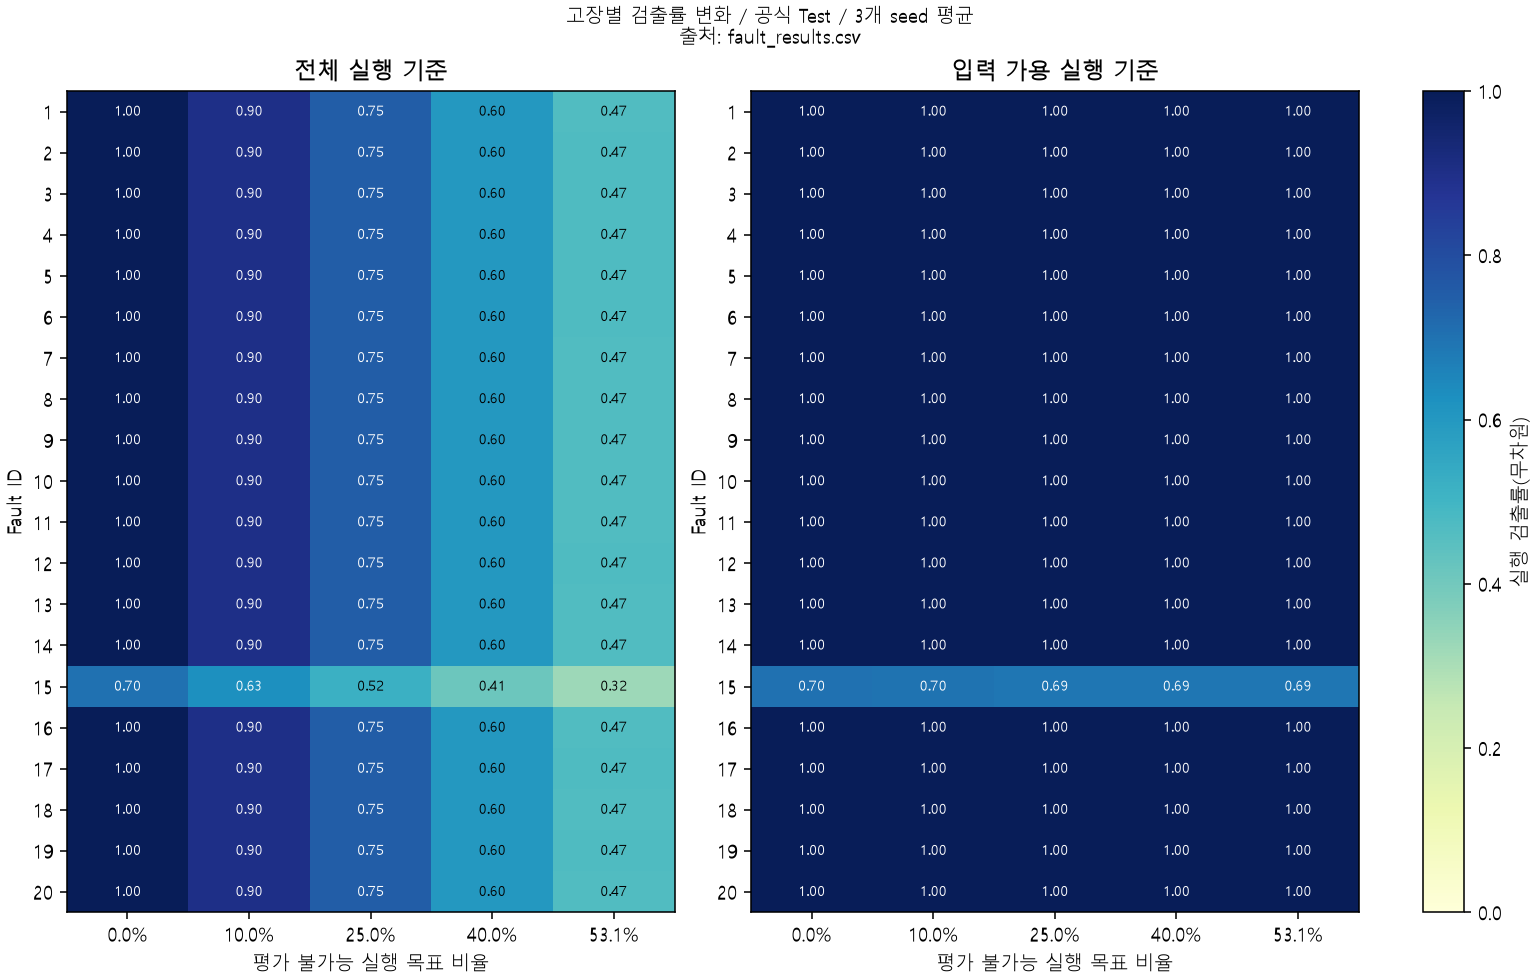

In [3]:
show(full[full.rate==.531][['seed','cause_A_no_input','cause_B_input_but_no_detection','detected_fault_runs','baseline_detections_lost','lost_previously_detected_due_unavailability']],
     '53.1% 조건의 배타적 결과와 실제 Baseline 검출 손실')
show(summary[['rate','detection_roc_auc','detection_f1','predicted_samples']] if 'predicted_samples' in summary else summary[['rate','detection_roc_auc','detection_f1']],
     '실제 유효 시점에서만 계산한 ROC-AUC/F1 / 평가집합 변경에 주의')
figure('fault_detection_heatmap.png')

## 3. Detection Delay: 사례구성 변화와 실제 지연 증가 구분

    주실험의입력이남은동일실행은원예측·시간축·임계값이같아짝지은지연변화가0이다. 전체요약중앙값도48분이지만평가불가실행은지연통계에서빠졌으므로입력손실의영향이없다는뜻이아니다.

rate,seed,detected_fault_runs,median_delay_minutes,mean_delay_minutes,p90_delay_minutes,paired_median_delay_change_minutes
0.00000,42,9851,48.00000,101.59649,174.00000,0.00000
0.00000,43,9851,48.00000,101.59649,174.00000,0.00000
0.00000,44,9851,48.00000,101.59649,174.00000,0.00000
0.10000,42,8859,48.00000,100.76566,171.00000,0.00000
0.10000,43,8871,48.00000,102.24315,174.00000,0.00000
0.10000,44,8862,48.00000,101.70413,174.00000,0.00000
0.25000,42,7378,48.00000,100.94199,171.00000,0.00000
0.25000,43,7389,48.00000,101.71214,174.00000,0.00000
0.25000,44,7382,48.00000,101.09537,174.00000,0.00000
0.40000,42,5901,48.00000,100.90442,171.00000,0.00000


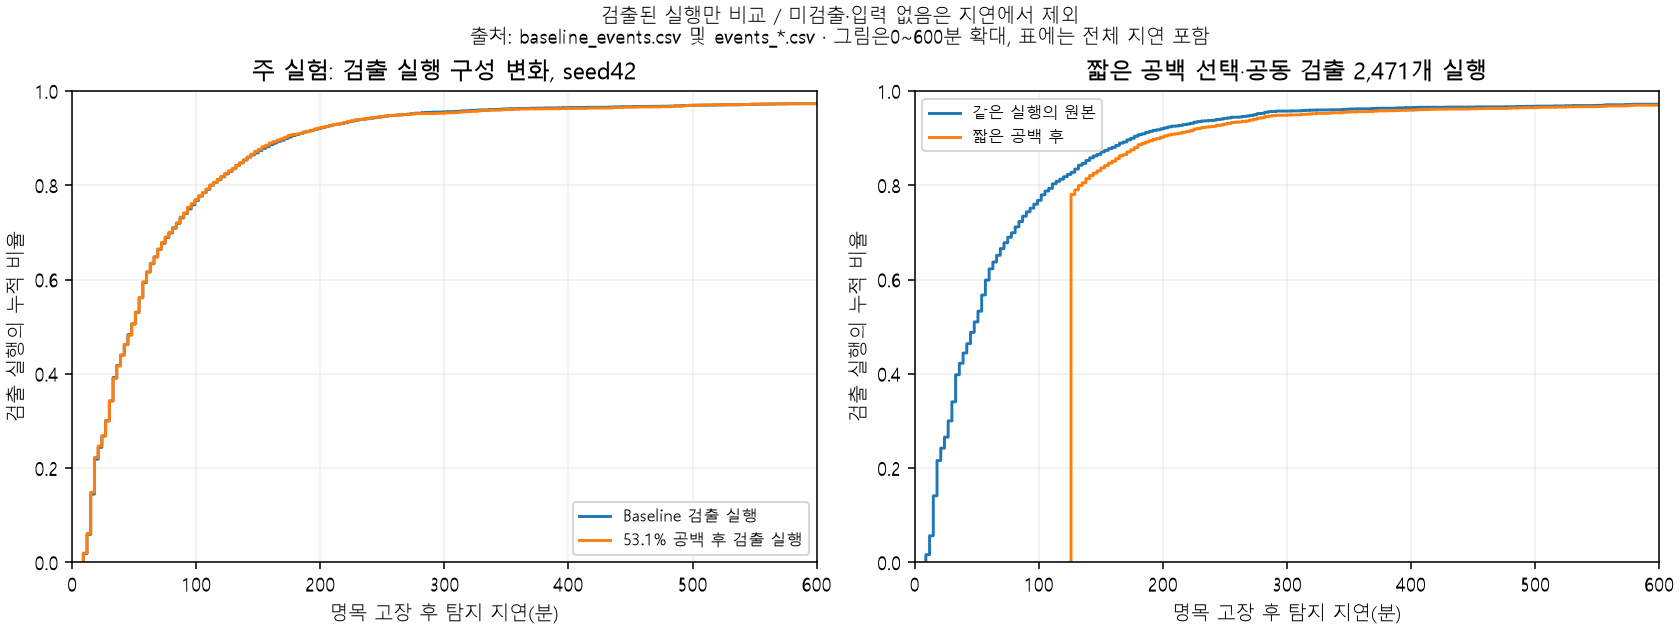

In [4]:
show(full[['rate','seed','detected_fault_runs','median_delay_minutes','mean_delay_minutes','p90_delay_minutes','paired_median_delay_change_minutes']],
     '주실험: 검출된실행의지연, 단위분; 미검출/입력없음은제외')
figure('delay_comparison.png')

## 4. 짧은 공백 대조군: 부분 가용은 평가 가능에 포함

    25%·seed42의동일2,500개실행에sample141~180만가렸다. 이후761/800입력창이남아평가불가는0,부분가용은2,500이다. 전체검출9,849개,전체지연중앙값72분이다. 공백선택·전후공동검출2,471개실행만짝지어보면지연차이중앙값은+81분이다. 두집단median의차이78분과paired차이median81분은다른통계다.

In [5]:
control=js('tables/summary_partial_control_r0.250_s42.json')
show(pd.DataFrame([{k:control[k] for k in ['total_fault_runs','evaluable_fault_runs','unavailable_fault_runs','partial_fault_runs','mean_post_input_availability_partial','detected_fault_runs','overall_detection_rate','median_delay_minutes','detection_f1']}]),
     '부분가용 대조군 / 입력가용비율95.125%, 전체평가범위유지')
show(table('partial_paired_delays.csv'),'동일실행의전후짝지은탐지지연, 단위분')
show(full[['rate','seed','normal_runs','normal_alarm_episodes','normal_exposure_hours','normal_alarm_episodes_per_hour']],
     '정상실행은가리지않아모든조건에서705 episodes/23,525h로동일')

total_fault_runs,evaluable_fault_runs,unavailable_fault_runs,partial_fault_runs,mean_post_input_availability_partial,detected_fault_runs,overall_detection_rate,median_delay_minutes,detection_f1
10000,10000,0,2500,0.95125,9849,0.98490,72.00000,0.92996


group,paired_detected_runs,baseline_delay_median,masked_delay_median,paired_delay_change_median
공백 선택 실행,2471,48.00000,126.00000,81.00000
공백 미선택 실행,7378,48.00000,48.00000,0.00000
전체 실행,9849,48.00000,72.00000,0.00000


rate,seed,normal_runs,normal_alarm_episodes,normal_exposure_hours,normal_alarm_episodes_per_hour
0.00000,42,500,705,23525.00000,0.02997
0.00000,43,500,705,23525.00000,0.02997
0.00000,44,500,705,23525.00000,0.02997
0.10000,42,500,705,23525.00000,0.02997
0.10000,43,500,705,23525.00000,0.02997
0.10000,44,500,705,23525.00000,0.02997
0.25000,42,500,705,23525.00000,0.02997
0.25000,43,500,705,23525.00000,0.02997
0.25000,44,500,705,23525.00000,0.02997
0.40000,42,500,705,23525.00000,0.02997


**해석 한계:** 이실험은가용시점의기존예측을선택한평가범위실험이다. 분류함수자체의성능저하를입증한것이아니다. 부분대조의F1이상승해도초기어려운시점이빠진영향일수있어모델개선이라고해석하지않는다. 입력1~2창만남은경우가용미검출에는3연속경보부족도포함될수있다.